## Задание 1

### Оценивание параметра сдвига

Рассматривается модель
$$X_i=\mu+U_i,\qquad U_i\sim N(0,1),$$
где неизвестен параметр сдвига $\mu$, а масштаб известен и равен 1.

Сравниваются выборочное среднее, медиана и M-оценки Губера и bisquare:
$$\bar X=\frac1n\sum_{i=1}^nX_i,\qquad
\hat\mu_{\mathrm{Med}}=\operatorname{Med}(X_1,\ldots,X_n).$$

M-оценки определяются уравнением
$$\sum_{i=1}^n\psi_c(X_i-\hat\mu)=0.$$

Для Губера
$$\psi_{H,c}(u)=\begin{cases}
-c,&u<-c,\\
u,&|u|\le c,\\
c,&u>c.
\end{cases}$$

Для bisquare
$$\psi_{B,c}(u)=u\left(1-\frac{u^2}{c^2}\right)^2
\mathbf1_{\{|u|<c\}}.$$

Обе функции ограничены. Используются параметры $c_H=1.345$ и $c_B=4.685$.
Оценки рассчитываются на выборке при истинном значении $\mu=2$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

mu_true = 2
n = 100

rng = np.random.default_rng(42)
x = rng.normal(loc=mu_true, scale=1, size=n)

In [2]:
mu_mean = np.mean(x)
mu_median = np.median(x)

c_huber = 1.345

mu_huber = brentq(
    lambda mu: np.mean(np.clip(x - mu, -c_huber, c_huber)),
    x.min(),
    x.max()
)

In [3]:
c_bisquare = 4.685
mu_bisquare = np.median(x)

for iteration in range(500):
    u = x - mu_bisquare
    weights = np.maximum(1 - (u / c_bisquare)**2, 0)**2
    mu_new = np.sum(weights * x) / np.sum(weights)

    if abs(mu_new - mu_bisquare) < 1e-8:
        mu_bisquare = mu_new
        break

    mu_bisquare = mu_new

,Оценка,Значение,Ошибка
0,Среднее,1.94973,-0.05027
1,Медиана,1.99785,-0.00215
2,Губер,1.95190,-0.04810
3,Bisquare,1.95649,-0.04351


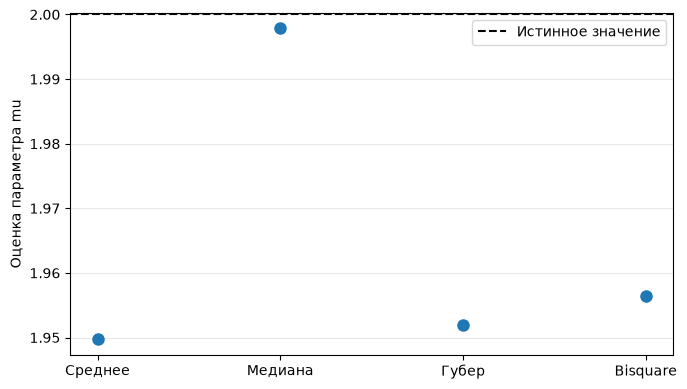

In [4]:
results = pd.DataFrame({
    "Оценка": ["Среднее", "Медиана", "Губер", "Bisquare"],
    "Значение": [mu_mean, mu_median, mu_huber, mu_bisquare]
})

results["Ошибка"] = results["Значение"] - mu_true

display(results.round(5))

plt.figure(figsize=(7, 4))
plt.plot(results["Оценка"], results["Значение"], "o", markersize=8)
plt.axhline(mu_true, color="black", linestyle="--", label="Истинное значение")
plt.ylabel("Оценка параметра mu")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Функции влияния

Функция влияния показывает чувствительность оценки к малому загрязнению распределения в точке $z$:
$$
\operatorname{IF}(z;T,F)=
\left.\frac{d}{d\varepsilon}
T\bigl((1-\varepsilon)F+\varepsilon\Delta_z\bigr)
\right|_{\varepsilon=0}.
$$

Для модели $X\sim N(\mu,1)$ обозначим $u=z-\mu$.

Для среднего:
$$\boxed{\operatorname{IF}_{\mathrm{mean}}(z)=z-\mu=u.}$$

Для медианы:
$$
\boxed{\operatorname{IF}_{\mathrm{Med}}(z)
=\frac{\operatorname{sign}(z-\mu)}{2f_X(\mu)}
=\sqrt{\frac{\pi}{2}}\operatorname{sign}(u).}
$$

Для M-оценки с функцией $\psi$:
$$
\boxed{\operatorname{IF}_{\psi}(z)
=\frac{\psi(u)}{\mathbb E[\psi'(U)]}},
\qquad U\sim N(0,1).
$$

Для Губера:
$$
\operatorname{IF}_{H}(z)
=\frac{\psi_{H,c}(u)}{2\Phi(c)-1}.
$$

Для bisquare:
$$
\operatorname{IF}_{B}(z)=\frac{\psi_{B,c}(u)}{A_B},
\qquad
A_B=\int_{-c}^{c}
\left(1-\frac{t^2}{c^2}\right)
\left(1-5\frac{t^2}{c^2}\right)\varphi(t)\,dt.
$$

Для bisquare рассматривается ветвь решения около истинного параметра.

Функция влияния среднего не ограничена. У медианы, Губера и bisquare она ограничена.
У bisquare влияние равно нулю при $|z-\mu|\ge c$.

In [5]:
from scipy.stats import norm
from scipy.integrate import quad

a_huber = 2 * norm.cdf(c_huber) - 1

a_bisquare = quad(
    lambda u: (
        (1 - (u / c_bisquare)**2)
        * (1 - 5 * (u / c_bisquare)**2)
        * norm.pdf(u)
    ),
    -c_bisquare,
    c_bisquare
)[0]

print(f"E[psi'_Huber(U)] = {a_huber:.5f}")
print(f"E[psi'_Bisquare(U)] = {a_bisquare:.5f}")

E[psi'_Huber(U)] = 0.82137
E[psi'_Bisquare(U)] = 0.75778


In [6]:
u_grid = np.linspace(-7, 7, 1401)

if_mean = u_grid
if_median = np.sqrt(np.pi / 2) * np.sign(u_grid)

if_huber = np.clip(u_grid, -c_huber, c_huber) / a_huber

if_bisquare = (u_grid * np.maximum(1 - (u_grid / c_bisquare)**2, 0)**2 / a_bisquare)

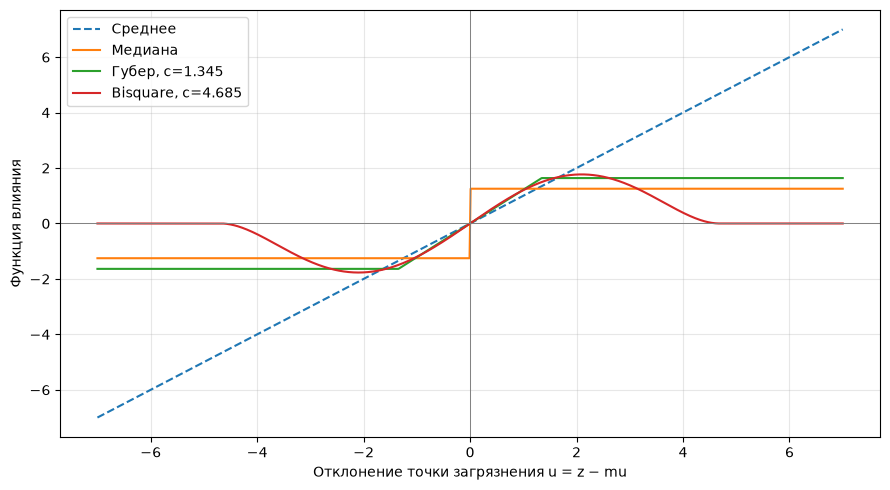

In [7]:
plt.figure(figsize=(9, 5))

plt.plot(u_grid, if_mean, label="Среднее", linestyle="--")
plt.plot(u_grid, if_median, label="Медиана")
plt.plot(u_grid, if_huber, label=f"Губер, c={c_huber}")
plt.plot(u_grid, if_bisquare, label=f"Bisquare, c={c_bisquare}")

plt.axhline(0, color="gray", linewidth=0.7)
plt.axvline(0, color="gray", linewidth=0.7)

plt.xlabel("Отклонение точки загрязнения u = z − mu")
plt.ylabel("Функция влияния")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Чувствительность к грубым ошибкам

Gross error sensitivity определяется как максимальное по модулю значение функции влияния:
$$
\boxed{\gamma^*(T,F)=\sup_z|\operatorname{IF}(z;T,F)|.}
$$

Для среднего функция влияния не ограничена:
$$\boxed{\gamma^*_{\mathrm{mean}}=\infty.}$$

Для медианы при $N(\mu,1)$:
$$
\boxed{\gamma^*_{\mathrm{Med}}=\sqrt{\frac{\pi}{2}}.}
$$

Для Губера максимум $|\psi_{H,c}(u)|$ равен $c$, поэтому
$$
\boxed{\gamma^*_H=\frac{c}{2\Phi(c)-1}.}
$$

Для bisquare максимум $|\psi_{B,c}(u)|$ достигается при
$|u|=c/\sqrt5$ и равен $16c/(25\sqrt5)$. Следовательно,
$$
\boxed{\gamma^*_B=\frac{16c}{25\sqrt5\,|A_B|}},
\qquad A_B=\mathbb E[\psi'_{B,c}(U)].
$$

Чем меньше $\gamma^*$, тем меньше максимальное влияние малого точечного загрязнения.

In [9]:
ges_mean = np.inf
ges_median = np.sqrt(np.pi / 2)

ges_huber = c_huber / a_huber
ges_bisquare = (16 * c_bisquare / (25 * np.sqrt(5) * abs(a_bisquare)))

In [10]:
ges_table = pd.DataFrame({
    "Оценка": ["Среднее", "Медиана", "Губер", "Bisquare"],
    "Gross error sensitivity": [ges_mean, ges_median, ges_huber, ges_bisquare]
})

display(ges_table.round(5))

,Оценка,Gross error sensitivity
0,Среднее,inf
1,Медиана,1.25331
2,Губер,1.63750
3,Bisquare,1.76955


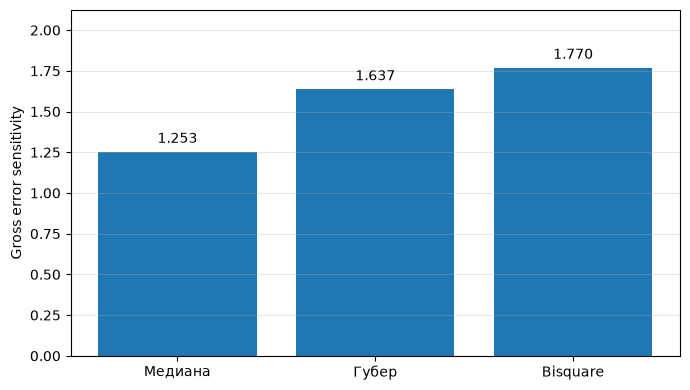

In [11]:
finite_ges = ges_table[np.isfinite(ges_table["Gross error sensitivity"])]

plt.figure(figsize=(7, 4))

bars = plt.bar(finite_ges["Оценка"], finite_ges["Gross error sensitivity"])

plt.bar_label(bars, fmt="%.3f", padding=4)
plt.ylim(0, finite_ges["Gross error sensitivity"].max() * 1.2)
plt.ylabel("Gross error sensitivity")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Эмпирическая проверка асимптотической дисперсии

При выполнении условий регулярности
$$
\sqrt n(\hat\mu_n-\mu)\xrightarrow{d}N(0,v^2),
\qquad
\boxed{v^2=\mathbb E_F[\operatorname{IF}(X;T,F)^2]}.
$$

Следовательно, при больших $n$:
$$
n\operatorname{Var}(\hat\mu_n)\approx v^2.
$$

Для модели $X\sim N(\mu,1)$ теоретические значения равны:
$$
v^2_{\mathrm{mean}}=1,\qquad
v^2_{\mathrm{Med}}=\frac{\pi}{2},
$$
$$
v^2_H=\frac{\mathbb E[\psi_{H,c}(U)^2]}{A_H^2},
\qquad
v^2_B=\frac{\mathbb E[\psi_{B,c}(U)^2]}{A_B^2},
\qquad U\sim N(0,1).
$$

Генерируем $R$ независимых выборок каждого объёма и в каждой заново вычисляем четыре оценки.
По повторениям находим
$$
\widehat v_n^2=
\frac{n}{R-1}\sum_{r=1}^{R}
\left(\hat\mu_n^{(r)}-\overline{\hat\mu}_n\right)^2.
$$

Отношение $\widehat v_n^2/v^2$ должно быть близко к единице.
При конечном числе повторений возможны случайные отклонения.
Для bisquare используется центральная ветвь решения с началом в медиане.

In [12]:
b_huber = quad(lambda u: u**2 * norm.pdf(u),-c_huber,c_huber)[0]

b_huber += 2 * c_huber**2 * norm.sf(c_huber)

b_bisquare = quad(lambda u: u**2 * (1 - (u / c_bisquare)**2)**4 * norm.pdf(u), -c_bisquare, c_bisquare)[0]

theoretical_variances = np.array([1,np.pi / 2,b_huber / a_huber**2,b_bisquare / a_bisquare**2])

names = ["Среднее", "Медиана", "Губер", "Bisquare"]

display(pd.DataFrame({"Оценка": names, "Теоретическая v²": theoretical_variances}).round(5))

,Оценка,Теоретическая v²
0,Среднее,1.00000
1,Медиана,1.57080
2,Губер,1.05263
3,Bisquare,1.05263


In [13]:
def m_estimates(sample):
    mu_h = brentq(lambda mu: np.mean(np.clip(sample - mu, -c_huber, c_huber)),sample.min(), sample.max())
    mu_b = np.median(sample)

    for iteration in range(500):
        u = sample - mu_b
        weights = np.maximum(1 - (u / c_bisquare)**2, 0)**2
        mu_new = np.sum(weights * sample) / np.sum(weights)

        if abs(mu_new - mu_b) < 1e-8:
            mu_b = mu_new
            break

        mu_b = mu_new

    return mu_h, mu_b

In [14]:
repeats = 2000
sample_sizes = [100, 500, 1000]
rng = np.random.default_rng(42)

rows = []

for n in sample_sizes:
    estimates = np.zeros((repeats, 4))

    for r in range(repeats):
        sample = rng.normal(loc=mu_true, scale=1, size=n)

        estimates[r, 0] = np.mean(sample)
        estimates[r, 1] = np.median(sample)
        estimates[r, 2:] = m_estimates(sample)

    empirical_variances = n * np.var(estimates, axis=0, ddof=1)

    for j, name in enumerate(names):
        rows.append([
            n,
            name,
            theoretical_variances[j],
            empirical_variances[j],
            empirical_variances[j] / theoretical_variances[j]
        ])

In [15]:
variance_check = pd.DataFrame(rows, columns=[
    "n",
    "Оценка",
    "Теоретическая v²",
    "Эмпирическая v²",
    "Отношение"
])

display(variance_check.round(5))

,n,Оценка,Теоретическая v²,Эмпирическая v²,Отношение
0,100,Среднее,1.00000,1.00534,1.00534
1,100,Медиана,1.57080,1.54153,0.98137
2,100,Губер,1.05263,1.06619,1.01288
3,100,Bisquare,1.05263,1.06844,1.01502
4,500,Среднее,1.00000,0.95471,0.95471
5,500,Медиана,1.57080,1.48693,0.94661
6,500,Губер,1.05263,0.99810,0.94820
7,500,Bisquare,1.05263,0.99756,0.94768
8,1000,Среднее,1.00000,0.98062,0.98062
9,1000,Медиана,1.57080,1.58446,1.00870


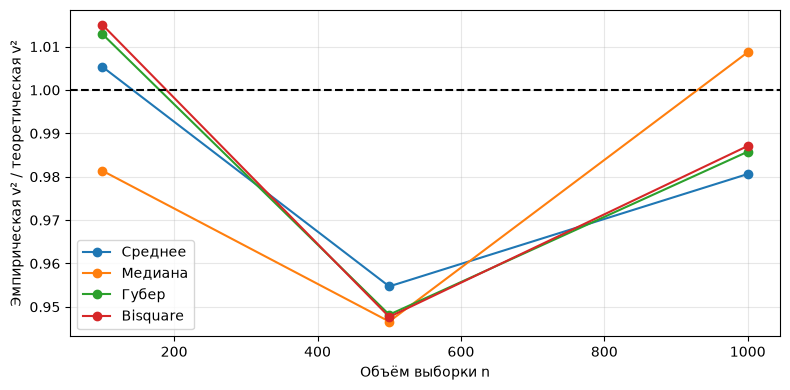

In [16]:
plt.figure(figsize=(8, 4))

for name in names:
    part = variance_check[variance_check["Оценка"] == name]
    plt.plot(part["n"], part["Отношение"], "o-", label=name)

plt.axhline(1, color="black", linestyle="--")
plt.xlabel("Объём выборки n")
plt.ylabel("Эмпирическая v² / теоретическая v²")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Задание 2

### Исследование breakdown point медианы

Рассматривается модель $X_i\sim N(\mu,1)$, где $\mu=2$.
Оценка положения:
$$\hat\mu=\operatorname{Med}(X_1,\ldots,X_n).$$

Breakdown point характеризует минимальную долю замен наблюдений,
при которой оценку можно сделать неограниченно далёкой от исходного значения.
Для медианы при чётном объёме выборки
$$\boxed{\varepsilon^*=\frac12.}$$

В каждой выборке заменяем $m$ наблюдений значением $\mu+M$:
$$
\widetilde X_i=
\begin{cases}
\mu+M,&i\le m,\\
X_i,&i>m,
\end{cases}
\qquad \varepsilon=\frac mn.
$$

Сравниваем несколько величин выбросов $M$ и доли загрязнения ниже,
на уровне и выше breakdown point.

Информативность оцениваем через смещение, RMSE и вероятность ошибки не более $\delta=1$:
$$
\operatorname{Bias}=\frac1R\sum_{r=1}^R(\hat\mu^{(r)}-\mu),
$$
$$
\operatorname{RMSE}=
\sqrt{\frac1R\sum_{r=1}^R(\hat\mu^{(r)}-\mu)^2},
\qquad
\widehat P_\delta=
\frac1R\sum_{r=1}^R
\mathbf1_{\{|\hat\mu^{(r)}-\mu|\le\delta\}}.
$$

При $\varepsilon<0.5$ медиана остаётся ограниченной при увеличении $M$,
хотя её ошибка может быть заметной. При $\varepsilon\ge0.5$ выбранное загрязнение
позволяет неограниченно увеличивать ошибку медианы вместе с $M$.

In [17]:
mu_true = 2
n = 200
repeats = 1000
breakdown_point = 0.5
tolerance = 1

contamination_levels = [0, 0.1, 0.25, 0.4, 0.45, 0.49, 0.5, 0.51, 0.6]
outlier_sizes = [10, 100, 1000]

rng = np.random.default_rng(42)
clean_samples = rng.normal(loc=mu_true, scale=1, size=(repeats, n))

In [18]:
rows = []

for outlier_size in outlier_sizes:
    for epsilon in contamination_levels:
        m = round(epsilon * n)

        samples = clean_samples.copy()
        samples[:, :m] = mu_true + outlier_size

        medians = np.median(samples, axis=1)
        errors = medians - mu_true

        bias = np.mean(errors)
        rmse = np.sqrt(np.mean(errors**2))
        accuracy = np.mean(np.abs(errors) <= tolerance)

        rows.append([m / n,outlier_size,np.mean(medians),bias,rmse,accuracy])

In [19]:
breakdown_results = pd.DataFrame(rows, columns=["Доля выбросов", "Величина выброса M", "Средняя оценка", "Смещение", "RMSE", "Вероятность ошибки ≤ 1"])

display(breakdown_results.round(4))

,Доля выбросов,Величина выброса M,Средняя оценка,Смещение,RMSE,Вероятность ошибки ≤ 1
0,0.00,10,1.9971,-0.0029,0.0878,1.000
1,0.10,10,2.1375,0.1375,0.1667,1.000
2,0.25,10,2.4262,0.4262,0.4382,1.000
3,0.40,10,2.9691,0.9691,0.9781,0.606
4,0.45,10,3.3329,1.3329,1.3431,0.010
5,0.49,10,4.0755,2.0755,2.0936,0.000
6,0.50,10,8.2656,6.2656,6.2697,0.000
7,0.51,10,12.0000,10.0000,10.0000,0.000
8,0.60,10,12.0000,10.0000,10.0000,0.000
9,0.00,100,1.9971,-0.0029,0.0878,1.000


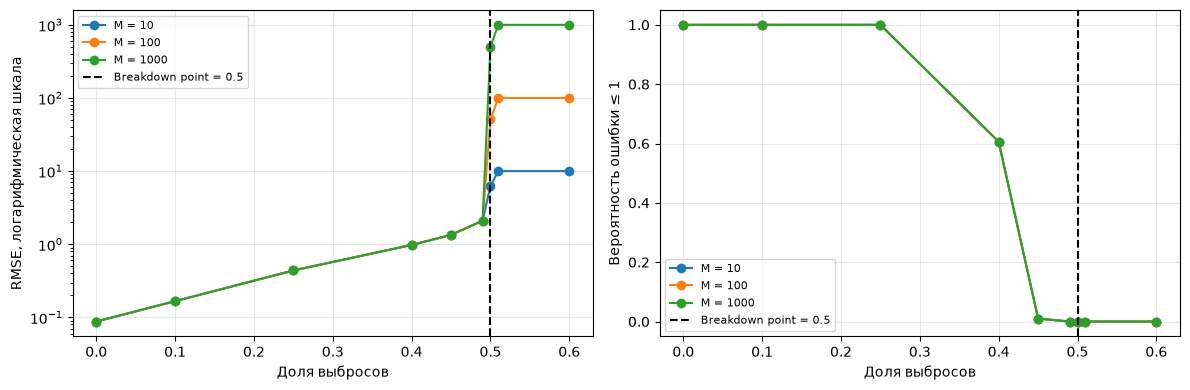

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for outlier_size in outlier_sizes:
    part = breakdown_results[breakdown_results["Величина выброса M"] == outlier_size]
    axes[0].plot(part["Доля выбросов"], part["RMSE"], "o-", label=f"M = {outlier_size}")
    axes[1].plot(part["Доля выбросов"], part["Вероятность ошибки ≤ 1"], "o-", label=f"M = {outlier_size}")

axes[0].set_yscale("log")
axes[0].set_ylabel("RMSE, логарифмическая шкала")
axes[1].set_ylabel("Вероятность ошибки ≤ 1")
axes[1].set_ylim(-0.05, 1.05)

for ax in axes:
    ax.axvline(breakdown_point, color="black", linestyle="--", label="Breakdown point = 0.5")
    ax.set_xlabel("Доля выбросов")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()